# Mortality Probabilities
This notebook explores the mortality table used in the life insurance framework.

It visualizes:
- the one-year death probability $q_x$ by age, separately for males and females
- the one-year survival probability $p_x$ by age, separately for males and females.
The survival probabilities are derived from the death probabilities using:
$
p_x = 1 - q_x
$

The plots help compare how mortality and survival probabilities develop across ages and between the two genders.

In [1]:
# Import libraries
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
# Load mortality data
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (PROJECT_ROOT / "data" / "processed" / "mortality_table.csv")

df = pd.read_csv(DATA_PATH)
df.head()

,age,qx_male,qx_female
0,0,0.003380,0.002972
1,1,0.000238,0.000234
2,2,0.000174,0.000128
3,3,0.000130,0.000115
4,4,0.000128,0.000068


In [3]:
# Create survival probabilities px (probability of surviving from age x to age x+1)
df['px_male'] = 1 - df['qx_male']
df['px_female'] = 1 - df['qx_female']
df.head()

,age,qx_male,qx_female,px_male,px_female
0,0,0.003380,0.002972,0.996620,0.997028
1,1,0.000238,0.000234,0.999762,0.999766
2,2,0.000174,0.000128,0.999826,0.999872
3,3,0.000130,0.000115,0.999870,0.999885
4,4,0.000128,0.000068,0.999872,0.999932


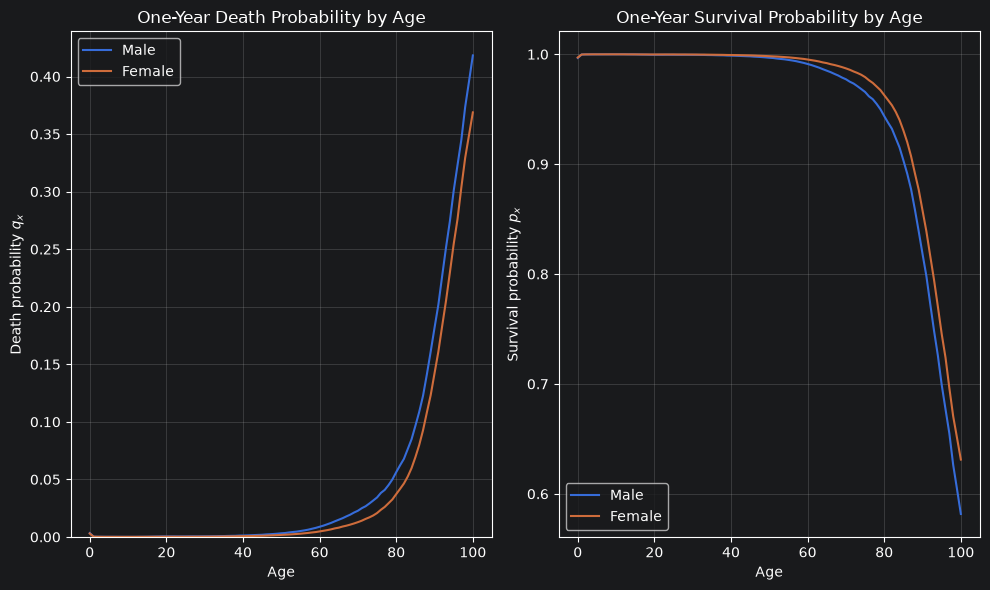

In [4]:
# Visualize death probabilities
fig, ax = plt.subplots(1,2,figsize=(10, 6))

ax[0].plot(df["age"], df["qx_male"], label="Male")
ax[0].plot(df["age"], df["qx_female"], label="Female")

ax[0].set_title("One-Year Death Probability by Age")
ax[0].set_xlabel("Age")
ax[0].set_ylabel("Death probability $q_x$")
ax[0].set_ylim(bottom=0)
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(df["age"], df["px_male"], label="Male")
ax[1].plot(df["age"], df["px_female"], label="Female")

ax[1].set_title("One-Year Survival Probability by Age")
ax[1].set_xlabel("Age")
ax[1].set_ylabel("Survival probability $p_x$")
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()

# save figure
FIGURE_PATH = (PROJECT_ROOT / "reports" / "figures" / "death_and_survival_probabilities_by_age.png")
fig.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")
plt.show()